# Implementing Knowledge Distillation

This notebook walks through a complete implementation of knowledge distillation with working code examples. We'll build everything from scratch and train a real student model.

## Setup and Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


torch.manual_seed(42)
np.random.seed(42)

# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.8.0+cpu


## Step 1: Temperature Scaling Function

Temperature controls how "smooth" the probability distribution becomes. Let's implement and test it:

In [2]:
def apply_temperature(logits, temperature):
    """
    Apply temperature scaling to logits.
    
    Args:
        logits: Raw model outputs before softmax
        temperature: Higher = softer probabilities
    
    Returns:
        Softened probability distribution
    """
    return F.softmax(logits / temperature, dim=-1)

#  sample logits
logits = torch.tensor([10.0, 2.0, 1.0, 0.5])

print("temp scaling examples:")
print("="*60)
for T in [1, 3, 5, 10]:
    probs = apply_temperature(logits, temperature=T)
    print(f"\nT={T:2d}: {probs.numpy()}")
    print(f"Entropy: {-(probs * torch.log(probs + 1e-10)).sum():.4f}")

print("\nHigher temperature = Higher entropy = More uncertainty revealed")

temp scaling examples:

T= 1: [9.9946660e-01 3.3528369e-04 1.2334397e-04 7.4811906e-05]
Entropy: 0.0050

T= 3: [0.86101913 0.05982659 0.04286762 0.03628666]
Entropy: 0.5527

T= 5: [0.6592983  0.13311003 0.10898128 0.09861033]
Entropy: 1.0131

T=10: [0.44590312 0.20035718 0.18129069 0.17244904]
Entropy: 1.2949

Higher temperature = Higher entropy = More uncertainty revealed


## Step 2: The Distillation Loss Function

The core of knowledge distillation - combining soft targets from the teacher with hard labels:

In [3]:
def distillation_loss(student_logits, teacher_logits, labels, temperature=3.0, alpha=0.7):
    """
    Calculate the knowledge distillation loss
    
    Args:
        student_logits: Raw outputs from student model
        teacher_logits: Raw outputs from teacher model
        labels: Ground truth labels
        temperature: Softening parameter (default: 3.0)
        alpha: Weight for distillation loss (default: 0.7)
    
    Returns:
        Combined loss value
    """
    # soften predictions using temperature
    soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
    soft_student = F.log_softmax(student_logits / temperature, dim=-1)
    
    # Distillation loss: KL divergence between teacher and student
    # Scaled by temperature^2 to account for magnitude change
    distill_loss = F.kl_div(
        soft_student, 
        soft_teacher, 
        reduction='batchmean') * (temperature ** 2)
    
    # Student loss: regular cross-entropy with true labels
    student_loss = F.cross_entropy(student_logits, labels)
    
    # Combine both losses
    total_loss = alpha * distill_loss + (1 - alpha) * student_loss
    
    return total_loss, distill_loss, student_loss

# test the loss function
print("Testing Distillation Loss Function:")


# Create dummy data
batch_size = 4
num_classes = 10
dummy_student = torch.randn(batch_size, num_classes)
dummy_teacher = torch.randn(batch_size, num_classes)
dummy_labels = torch.randint(0, num_classes, (batch_size,))

total, distill, student = distillation_loss(dummy_student, dummy_teacher, dummy_labels, temperature=3.0, alpha=0.7)

print(f"Total Loss: {total:.4f}")
print(f"Distillation Loss: {distill:.4f} (weight: 0.7)")
print(f"Student Loss: {student:.4f} (weight: 0.3)")
print(f"\nVerify: {0.7*distill + 0.3*student:.4f} = {total:.4f}")

Testing Distillation Loss Function:
Total Loss: 1.5987
Distillation Loss: 0.8083 (weight: 0.7)
Student Loss: 3.4429 (weight: 0.3)

Verify: 1.5987 = 1.5987


## Step 3: Define Teacher and Student Models

Let's create realistic models for image classification (e.g., MNIST-style):

In [4]:
class TeacherModel(nn.Module):
    """Large model with many parameters"""
    def __init__(self, input_size=784, num_classes=10):
        super(TeacherModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        return self.network(x)

class StudentModel(nn.Module):
    """Small model with fewer parameters"""
    def __init__(self, input_size=784, num_classes=10):
        super(StudentModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )
    
    def forward(self, x):
        return self.network(x)

#  model instances
teacher = TeacherModel().to(device)
student = StudentModel().to(device)

# count parameters
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

teacher_params = count_parameters(teacher)
student_params = count_parameters(student)

print("model architecture comparison:")
print(f"Teacher parameters: {teacher_params:,}")
print(f"Student parameters: {student_params:,}")
print(f"Compression ratio: {teacher_params/student_params:.1f}x")
print(f"Size reduction: {(1-student_params/teacher_params)*100:.1f}%")

print("\nTeacher Architecture:")
print(teacher)
print("\nStudent Architecture:")
print(student)

model architecture comparison:
Teacher parameters: 1,462,538
Student parameters: 109,386
Compression ratio: 13.4x
Size reduction: 92.5%

Teacher Architecture:
TeacherModel(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=256, out_features=10, bias=True)
  )
)

Student Architecture:
StudentModel(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


## Step 4: Create Synthetic Dataset

For this example, we'll create synthetic data to demonstrate the training process:

In [5]:
# Create synthetic dataset
def create_synthetic_data(n_samples=1000, input_size=784, num_classes=10):
    """
    Create synthetic classification data.
    """
    # Generate random features + Generate random labels
    X = torch.randn(n_samples, input_size)
    y = torch.randint(0, num_classes, (n_samples,))
    
    return X, y

# Create training and test data
train_X, train_y = create_synthetic_data(n_samples=2000)
test_X, test_y = create_synthetic_data(n_samples=500)

# Create data loaders
train_dataset = TensorDataset(train_X, train_y)
test_dataset = TensorDataset(test_X, test_y)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Batch size: {train_loader.batch_size}")
print(f"Number of batches: {len(train_loader)}")

Training samples: 2000
Test samples: 500
Batch size: 64
Number of batches: 32


## Step 5: Pre-train the Teacher Model

First, we need a well-trained teacher. Let's train it on our data:

Training Teacher Model...
Epoch 3/15, Loss: 1.4952
Epoch 3/15, Loss: 1.4952
Epoch 6/15, Loss: 0.1058
Epoch 6/15, Loss: 0.1058
Epoch 9/15, Loss: 0.0580
Epoch 9/15, Loss: 0.0580
Epoch 12/15, Loss: 0.0429
Epoch 12/15, Loss: 0.0429
Epoch 15/15, Loss: 0.0561
Epoch 15/15, Loss: 0.0561


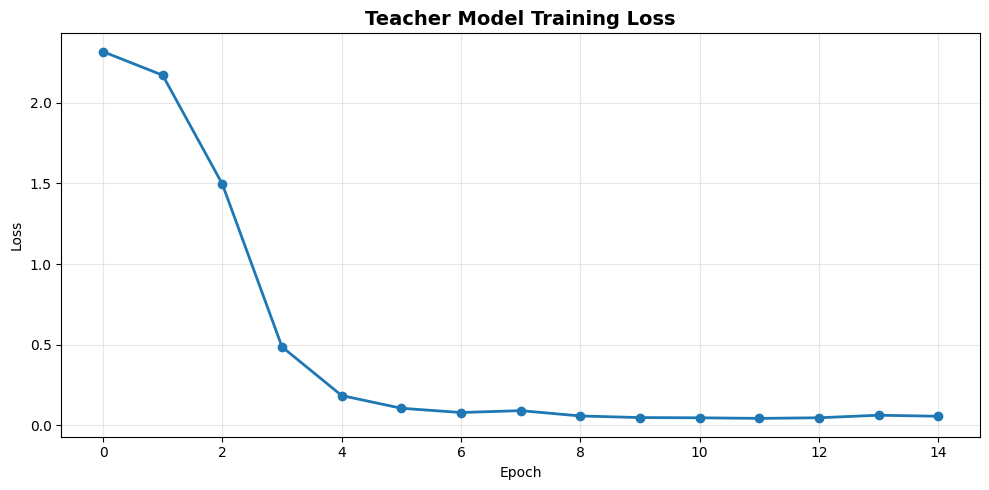


Final teacher loss: 0.0561


In [6]:
#  Train the teacher model using standard supervised learning.
def train_teacher(model, train_loader, num_epochs=15, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.train()
    
    losses = []
    
    print("Training Teacher Model...")
    for epoch in range(num_epochs):
        epoch_loss = 0
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = F.cross_entropy(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
        
        avg_loss = epoch_loss / len(train_loader)
        losses.append(avg_loss)
        
        if (epoch + 1) % 3 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}")
    
    return losses

# Train the teacher
teacher_losses = train_teacher(teacher, train_loader, num_epochs=15)

# Plot training curve
plt.figure(figsize=(10, 5))
plt.plot(teacher_losses, marker='o', linewidth=2, markersize=6)
plt.title('Teacher Model Training Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nFinal teacher loss: {teacher_losses[-1]:.4f}")

## Step 6: Train Student with Distillation

Now train the student model using knowledge distillation:

In [7]:
def train_student_distillation(student_model, teacher_model, train_loader, num_epochs=15, temperature=4.0, alpha=0.7, lr=0.001):
    """
    Train student model using knowledge distillation.
    """
    optimizer = optim.Adam(student_model.parameters(), lr=lr)
    teacher_model.eval()  # eval mode
    
    losses = []
    distill_losses = []
    student_losses = []
    
    print(f"Training Student with Distillation (T={temperature}, α={alpha})...")
    
    for epoch in range(num_epochs):
        student_model.train()
        epoch_loss = 0
        epoch_distill = 0
        epoch_student = 0
        
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            
            # Get teacher predictions (no gradients)
            with torch.no_grad():
                teacher_logits = teacher_model(batch_X)
            
            # Get student predictions
            student_logits = student_model(batch_X)
            
            # Calculate distillation loss
            total_loss, distill_loss, stud_loss = distillation_loss(student_logits, teacher_logits, batch_y,temperature=temperature, alpha=alpha)
            
            # Backprop
            total_loss.backward()
            optimizer.step()
            
            epoch_loss += total_loss.item()
            epoch_distill += distill_loss.item()
            epoch_student += stud_loss.item()
        
        avg_loss = epoch_loss / len(train_loader)
        avg_distill = epoch_distill / len(train_loader)
        avg_student = epoch_student / len(train_loader)
        
        losses.append(avg_loss)
        distill_losses.append(avg_distill)
        student_losses.append(avg_student)
        
        if (epoch + 1) % 3 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} | "
                  f"Total: {avg_loss:.4f} | "
                  f"Distill: {avg_distill:.4f} | "
                  f"Student: {avg_student:.4f}")
    
    return losses, distill_losses, student_losses

# train student with distillation
student_losses, distill_losses, hard_losses = train_student_distillation(student, teacher, train_loader,num_epochs=15, temperature=4.0, alpha=0.7)

Training Student with Distillation (T=4.0, α=0.7)...
Epoch 3/15 | Total: 14.3919 | Distill: 19.7609 | Student: 1.8640
Epoch 3/15 | Total: 14.3919 | Distill: 19.7609 | Student: 1.8640
Epoch 6/15 | Total: 4.3665 | Distill: 6.0301 | Student: 0.4847
Epoch 6/15 | Total: 4.3665 | Distill: 6.0301 | Student: 0.4847
Epoch 9/15 | Total: 1.4253 | Distill: 2.0071 | Student: 0.0677
Epoch 9/15 | Total: 1.4253 | Distill: 2.0071 | Student: 0.0677
Epoch 12/15 | Total: 1.0687 | Distill: 1.5080 | Student: 0.0437
Epoch 12/15 | Total: 1.0687 | Distill: 1.5080 | Student: 0.0437
Epoch 15/15 | Total: 0.9565 | Distill: 1.3447 | Student: 0.0505
Epoch 15/15 | Total: 0.9565 | Distill: 1.3447 | Student: 0.0505


## Step 7: Visualize Training Progress

Let's visualize how the different loss components evolved:

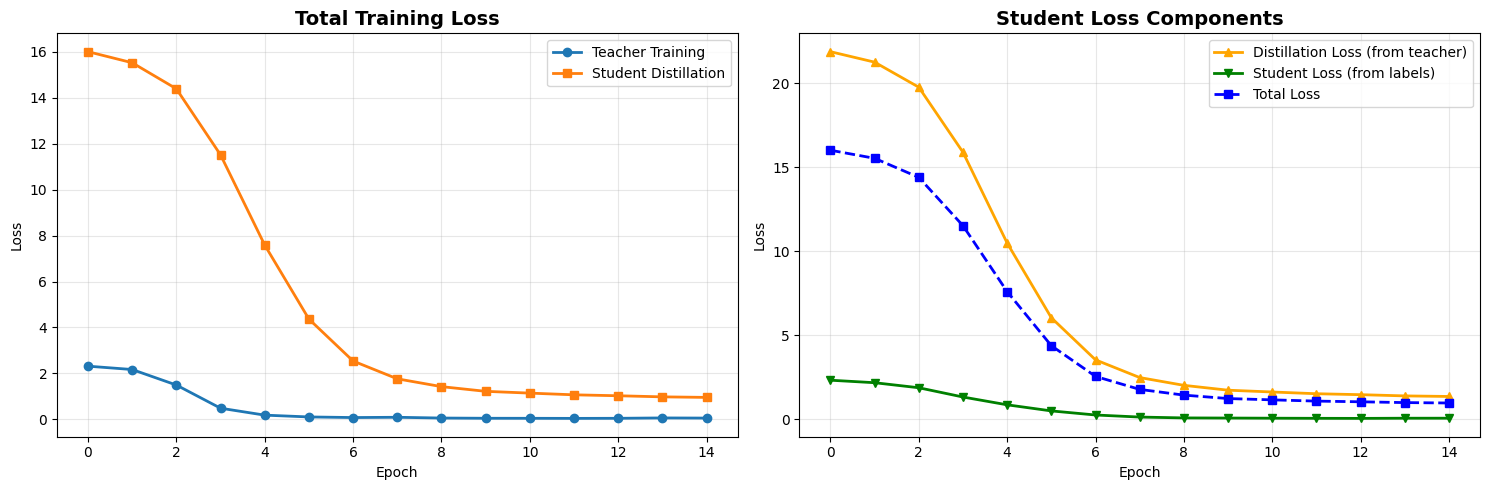

Notice how the student learns from both the teacher (distillation loss)
and the true labels (student loss)!


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# loss comparison
axes[0].plot(teacher_losses, label='Teacher Training', marker='o', linewidth=2)
axes[0].plot(student_losses, label='Student Distillation', marker='s', linewidth=2)
axes[0].set_title('Total Training Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Breakdown of student losses
axes[1].plot(distill_losses, label='Distillation Loss (from teacher)', 
             marker='^', linewidth=2, color='orange')
axes[1].plot(hard_losses, label='Student Loss (from labels)', 
             marker='v', linewidth=2, color='green')
axes[1].plot(student_losses, label='Total Loss', 
             marker='s', linewidth=2, color='blue', linestyle='--')
axes[1].set_title('Student Loss Components', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Notice how the student learns from both the teacher (distillation loss)")
print("and the true labels (student loss)!")

## Step 8: Evaluate and Compare Models

Let's evaluate both models on the test set:

In [9]:
# Evaluate model accuracy on test set.
def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == batch_y).sum().item()
            total += batch_y.size(0)
    
    accuracy = 100 * correct / total
    return accuracy

# EvaL both models
teacher_acc = evaluate_model(teacher, test_loader)
student_acc = evaluate_model(student, test_loader)

print("Model Evaluation Results:")
print(f"Teacher Accuracy:{teacher_acc:.2f}%")
print(f"Student Accuracy: {student_acc:.2f}%")
print(f"Accuracy Gap: {teacher_acc - student_acc:.2f}%")
print(f"Performance Retained: {(student_acc/teacher_acc)*100:.1f}%")
print(f"\nModel Size Comparison:")
print(f"Teacher params:{teacher_params:,}")
print(f"Student params:{student_params:,}")
print(f"Compression: {teacher_params/student_params:.1f}x smaller")

Model Evaluation Results:
Teacher Accuracy:11.00%
Student Accuracy: 10.20%
Accuracy Gap: 0.80%
Performance Retained: 92.7%

Model Size Comparison:
Teacher params:1,462,538
Student params:109,386
Compression: 13.4x smaller


## Step 9: Compare with Baseline Student

Let's train a student from scratch (without distillation) to see the benefit:

In [10]:
# BASELINE MODEL    
baseline_student = StudentModel().to(device)

# Train without distillation
print("Training Baseline student (without distillation)...")
baseline_losses = train_teacher(baseline_student, train_loader, num_epochs=15)

# eval 
baseline_acc = evaluate_model(baseline_student, test_loader)
print("Final Comparison:")
print(f"Teacher (large model):{teacher_acc:.2f}%")
print(f"Student with Distillation: {student_acc:.2f}%")
print(f"Student without Distillation:s{baseline_acc:.2f}%")
print(f"\nDistillation Improvement: +{student_acc - baseline_acc:.2f}%")
print(f"Gap to Teacher (with distillation): {teacher_acc - student_acc:.2f}%")
print(f"Gap to Teacher (baseline):{teacher_acc - baseline_acc:.2f}%")

Training Baseline student (without distillation)...
Training Teacher Model...
Epoch 3/15, Loss: 1.8856Epoch 3/15, Loss: 1.8856
Epoch 6/15, Loss: 0.3708

Epoch 6/15, Loss: 0.3708
Epoch 9/15, Loss: 0.0743
Epoch 12/15, Loss: 0.0373
Epoch 9/15, Loss: 0.0743
Epoch 12/15, Loss: 0.0373
Epoch 15/15, Loss: 0.0265
Final Comparison:
Teacher (large model):11.00%
Student with Distillation: 10.20%
Student without Distillation:s9.40%

Distillation Improvement: +0.80%
Gap to Teacher (with distillation): 0.80%
Gap to Teacher (baseline):1.60%
Epoch 15/15, Loss: 0.0265
Final Comparison:
Teacher (large model):11.00%
Student with Distillation: 10.20%
Student without Distillation:s9.40%

Distillation Improvement: +0.80%
Gap to Teacher (with distillation): 0.80%
Gap to Teacher (baseline):1.60%


## Step 10: Hyperparameter Exploration

Let's experiment with different temperatures and alpha values:

In [11]:
# Experiment with different hyperparameters
configs = [
    {'temperature': 2.0, 'alpha': 0.5},
    {'temperature': 4.0, 'alpha': 0.7},
    {'temperature': 6.0, 'alpha': 0.9},]

results = []

print("hyperparameter exploration:")


for config in configs:
    # Createstudent
    test_student = StudentModel().to(device)
    
    # Train
    print(f"\nTesting T={config['temperature']}, α={config['alpha']}")
    _, _, _ = train_student_distillation(
        test_student, teacher, train_loader,
        num_epochs=10,
        temperature=config['temperature'],
        alpha=config['alpha'],
        lr=0.001)
    
    # eval
    acc = evaluate_model(test_student, test_loader)
    results.append({
        'Temperature': config['temperature'],
        'Alpha': config['alpha'],
        'Accuracy': acc})
    print(f"Result: {acc:.2f}%")

# results
import pandas as pd
df_results = pd.DataFrame(results)
print("Results Summary:")
print(df_results.to_string(index=False))
print("\nBest configuration:", df_results.loc[df_results['Accuracy'].idxmax()].to_dict())

hyperparameter exploration:

Testing T=2.0, α=0.5
Training Student with Distillation (T=2.0, α=0.5)...
Epoch 3/10 | Total: 4.6756 | Distill: 7.5107 | Student: 1.8406
Epoch 3/10 | Total: 4.6756 | Distill: 7.5107 | Student: 1.8406
Epoch 6/10 | Total: 1.1695 | Distill: 2.0500 | Student: 0.2890
Epoch 6/10 | Total: 1.1695 | Distill: 2.0500 | Student: 0.2890
Epoch 9/10 | Total: 0.2811 | Distill: 0.5207 | Student: 0.0414
Result: 12.00%

Testing T=4.0, α=0.7
Training Student with Distillation (T=4.0, α=0.7)...
Epoch 9/10 | Total: 0.2811 | Distill: 0.5207 | Student: 0.0414
Result: 12.00%

Testing T=4.0, α=0.7
Training Student with Distillation (T=4.0, α=0.7)...
Epoch 3/10 | Total: 14.2591 | Distill: 19.5572 | Student: 1.8970
Epoch 3/10 | Total: 14.2591 | Distill: 19.5572 | Student: 1.8970
Epoch 6/10 | Total: 4.5237 | Distill: 6.2499 | Student: 0.4960
Epoch 6/10 | Total: 4.5237 | Distill: 6.2499 | Student: 0.4960
Epoch 9/10 | Total: 1.5015 | Distill: 2.1091 | Student: 0.0837
Result: 9.20%

Testi

## Key Takeaways

1. **Distillation works**: Students trained with distillation outperform those trained from scratch
2. **Temperature matters**: Higher temperature reveals more information but can be too soft
3. **Alpha balances**: Need to balance between teacher knowledge and true labels
4. **Compression achieved**: Much smaller models with minimal accuracy loss

## Hyperparameter Guidelines

- **Temperature (T)**: Start with 3-5, increase if student struggles, decrease if too different from teacher
- **Alpha (α)**: Start with 0.7, increase to rely more on teacher, decrease for more label supervision
- **Learning rate**: Often same or slightly higher than teacher's original LR
